# Arena de Personagens: o SVM consegue prever o vencedor de uma batalha Pokémon?

**Inteligência Artificial II · Checkpoint 1 (CONSTRUIR)**
**Grupo:** Luan (dados/EDA) · Gustavo (pré-processamento) · Anthony (experimentos) · Lucas (protótipo) · Alceu (comunicação)

Este notebook executa o **primeiro fluxo ponta a ponta** do projeto:

> Problema → Dados → EDA → Preparação → Baseline → Primeiro modelo (SVM) → Métricas

## 1. Problema e pergunta de investigação

**Problema:** em jogos de batalha, jogadores escolhem personagens sem saber quem tem vantagem no confronto. Prever o
favorito a partir apenas das características dos personagens (atributos e tipos) ajuda a entender **o que realmente
decide uma batalha**.

**Usuário/contexto:** jogadores e fãs. Na aplicação final, duas pessoas escolhem (ou sorteiam) um Pokémon cada e o
sistema prevê quem é o favorito, com a confiança da previsão.

**Pergunta de investigação:**
> Um classificador SVM, usando apenas os atributos e os tipos dos dois Pokémon, consegue prever o vencedor de batalhas
> entre **Pokémon que nunca viu no treino**, superando regras simples como "vence o mais rápido"?

**Variável-alvo:** `a_vence` (1 = o Pokémon A é o favorito, 0 = o B é o favorito).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sys.path.insert(0, "../src")
from simulador import eficacia   # tabela oficial de tipos (PokéAPI)

plt.rcParams["figure.dpi"] = 110
SEED = 42
ATRIBUTOS = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]

## 2. Dados

São **duas bases**, ambas reproduzíveis a partir do repositório:

| Base | Origem | Como é gerada |
|---|---|---|
| `pokemon.csv` | [PokéAPI](https://github.com/PokeAPI/pokeapi) (licença BSD-3): atributos oficiais dos jogos, gerações 1–9 | `python src/montar_base.py` |
| `batalhas.csv` | **Gerada pelo grupo** com um simulador baseado na fórmula de dano dos jogos | `python src/gerar_batalhas.py` (seed 42) |

**Por que gerar as batalhas?** O dataset público de batalhas (Kaggle, *Pokemon Challenge*) cobre só as gerações 1–6 e
foi produzido por um algoritmo desconhecido, cujas regras não estão documentadas. O nosso simulador usa a fórmula de dano
oficial, tem regras documentadas em `src/simulador.py` e cobre as 9 gerações.

### 2.1 Base de Pokémon

In [2]:
pk = pd.read_csv("../data/processed/pokemon.csv")
print(pk.shape)
pk.head()

(1242, 18)


,pokeapi_id,name,species,species_id,Generation,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,is_legendary,is_mythical,is_mega,is_forma_alternativa
0,1,bulbasaur,bulbasaur,1,1,Grass,Poison,318,45,49,49,65,65,45,0,0,False,False
1,2,ivysaur,ivysaur,2,1,Grass,Poison,405,60,62,63,80,80,60,0,0,False,False
2,3,venusaur,venusaur,3,1,Grass,Poison,525,80,82,83,100,100,80,0,0,False,False
3,4,charmander,charmander,4,1,Fire,NaN,309,39,52,43,60,50,65,0,0,False,False
4,5,charmeleon,charmeleon,5,1,Fire,NaN,405,58,64,58,80,65,80,0,0,False,False


| Coluna | Significado |
|---|---|
| `HP` | Pontos de vida: quanto dano aguenta |
| `Attack` / `Sp. Atk` | Força dos ataques físicos / especiais |
| `Defense` / `Sp. Def` | Resistência a ataques físicos / especiais |
| `Speed` | Define quem ataca primeiro |
| `Type 1`, `Type 2` | Tipos (Fogo, Água...); determinam vantagens (2×), resistências (0,5×) e imunidades (0×) |
| `Generation` | Geração em que a espécie foi lançada (1 a 9) |

In [3]:
print("Valores ausentes:\n", pk.isna().sum()[pk.isna().sum() > 0], sep="")
print("\nNomes duplicados:", pk["name"].duplicated().sum())
print("Pokémon por grupo de gerações:", pk.groupby(np.where(pk.Generation <= 6, "gerações 1–6", "gerações 7–9")).size().to_dict())
pk[ATRIBUTOS + ["Total"]].describe().round(1)

Valores ausentes:
Type 2    546
dtype: int64

Nomes duplicados: 0
Pokémon por grupo de gerações: {'gerações 1–6': 899, 'gerações 7–9': 343}


,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Total
count,1242.0,1242.0,1242.0,1242.0,1242.0,1242.0,1242.0
mean,71.5,82.5,76.1,74.9,73.6,70.7,449.2
std,26.5,32.9,30.7,34.2,27.7,30.6,122.7
min,1.0,5.0,5.0,10.0,20.0,5.0,175.0
25%,55.0,60.0,55.0,50.0,53.0,46.0,335.0
50%,70.0,80.0,70.0,68.0,70.0,70.0,473.5
75%,85.0,103.0,95.0,95.0,90.0,92.0,530.0
max,255.0,190.0,230.0,216.0,230.0,200.0,780.0


**Qualidade dos dados:**
- O único campo ausente é `Type 2`, que fica vazio quando o Pokémon tem um tipo só (não é erro).
- O script `montar_base.py` já removeu **66 formas cosméticas ou especiais** (Gigantamax, Totem, Pikachu com boné...) e
  **43 formas repetidas** (mesmos atributos e tipos da forma principal).
- **Escalas:** todos os atributos estão na mesma unidade (0 a 255), mas com distribuições diferentes. Como o SVM se baseia
  em distâncias, vamos **padronizar** (`StandardScaler`).

In [4]:
extremos = pd.concat([pk.nsmallest(3, "HP"), pk.nlargest(3, "HP"), pk.nlargest(3, "Total")])
extremos[["name", "Generation", "Total"] + ATRIBUTOS].drop_duplicates()

,name,Generation,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
291,shedinja,3,236,1,90,45,30,30,40
49,diglett,1,265,10,55,25,35,45,95
959,wiglett,9,245,10,55,25,35,25,95
241,blissey,2,540,255,10,10,75,135,55
112,chansey,1,450,250,5,5,35,105,50
798,guzzlord,7,570,223,101,53,97,53,43
1064,mewtwo-mega-x,1,780,106,190,100,154,100,130
1065,mewtwo-mega-y,1,780,106,150,70,194,120,140
1100,rayquaza-mega,3,780,105,180,100,180,100,115


**Outliers relevantes (não são erros, são casos reais do jogo):** Shedinja tem **HP = 1** (morre com qualquer golpe),
Blissey e Chansey têm HP enorme e ataque mínimo, e as formas Mega/Primal e Eternatus têm Total muito acima da média.
Esses casos ficam na base, mas serão acompanhados na análise de erros.

### 2.2 Base de batalhas (gerada)

In [5]:
bt = pd.read_csv("../data/processed/batalhas.csv")
print(bt.shape)
print(bt.groupby("grupo").agg(confrontos=("a_vence", "size"), pct_a_vence=("a_vence", "mean")).round(3))
bt.head()

(40000, 6)
        confrontos  pct_a_vence
grupo                          
misto         4000        0.513
teste         6000        0.504
treino       30000        0.494


,a_id,b_id,grupo,vitorias_a,prob_a,a_vence
0,1,97,treino,0,0.0000,0
1,1,117,treino,21,1.0000,1
2,1,131,treino,0,0.0000,0
3,1,154,treino,17,0.8095,1
4,1,158,treino,21,1.0000,1


- Cada linha é um **confronto A × B simulado 21 vezes**. `vitorias_a` é quantas vezes A venceu, `prob_a` é a fração, e
  `a_vence = 1` se A venceu a maioria.
- As **classes estão equilibradas** (cerca de 50% em cada grupo), porque a posição A/B é sorteada. Por isso, acurácia é uma
  métrica aceitável aqui, complementada por F1 e ROC-AUC.
- Grupos: `treino` (as duas espécies das gerações 1–6), `teste` (as duas das gerações 7–9) e `misto` (reservado).

### 2.3 Vazamento de dados (*data leakage*)

Se as batalhas fossem divididas aleatoriamente entre treino e teste, **o mesmo Pokémon apareceria nos dois lados**. O
modelo poderia "decorar" que o Mewtwo vence quase sempre e o resultado ficaria inflado. Para evitar isso, a divisão é feita
**por Pokémon, usando a geração**:
- **Treino:** batalhas só entre Pokémon das gerações 1–6.
- **Teste:** batalhas só entre Pokémon das gerações 7–9, **que o modelo nunca viu**.

In [6]:
treino, teste = bt[bt.grupo == "treino"], bt[bt.grupo == "teste"]
ids_treino = set(treino.a_id) | set(treino.b_id)
ids_teste = set(teste.a_id) | set(teste.b_id)
print(f"Pokémon no treino: {len(ids_treino)} | no teste: {len(ids_teste)} | em comum: {len(ids_treino & ids_teste)}")

Pokémon no treino: 899 | no teste: 343 | em comum: 0


## 3. Análise exploratória (EDA)

In [7]:
# Junta os atributos de A e B em cada confronto
info = pk.set_index("pokeapi_id")

def juntar(df):
    a = info.loc[df.a_id].reset_index(drop=True).add_prefix("a_")
    b = info.loc[df.b_id].reset_index(drop=True).add_prefix("b_")
    return pd.concat([df.reset_index(drop=True), a, b], axis=1)

def melhor_mult(tipos_atk, t1, t2):
    """Multiplicador do melhor golpe do atacante: STAB 1,5 × eficácia, ou golpe Normal sem STAB."""
    opcoes = [1.5 * eficacia(t, t1, t2) for t in tipos_atk if isinstance(t, str)]
    if "Normal" not in tipos_atk:
        opcoes.append(eficacia("Normal", t1, t2))
    return max(max(opcoes), 1.0 if max(opcoes) == 0 else 0)   # imunidade total -> "Esforço" (1×)

def add_tipos(d):
    d["mult_a"] = [melhor_mult((r.a_Type_1, r.a_Type_2), r.b_Type_1, r.b_Type_2) for r in d.itertuples()]
    d["mult_b"] = [melhor_mult((r.b_Type_1, r.b_Type_2), r.a_Type_1, r.a_Type_2) for r in d.itertuples()]
    d["vantagem_tipo"] = (np.log2(d.mult_a) - np.log2(d.mult_b)).round(2)
    return d

eda = add_tipos(juntar(treino).rename(columns=lambda c: c.replace(" ", "_")))
eda["dif_speed"] = eda.a_Speed - eda.b_Speed
eda["dif_total"] = eda.a_Total - eda.b_Total

**Pergunta 1: o mais rápido vence sempre?**

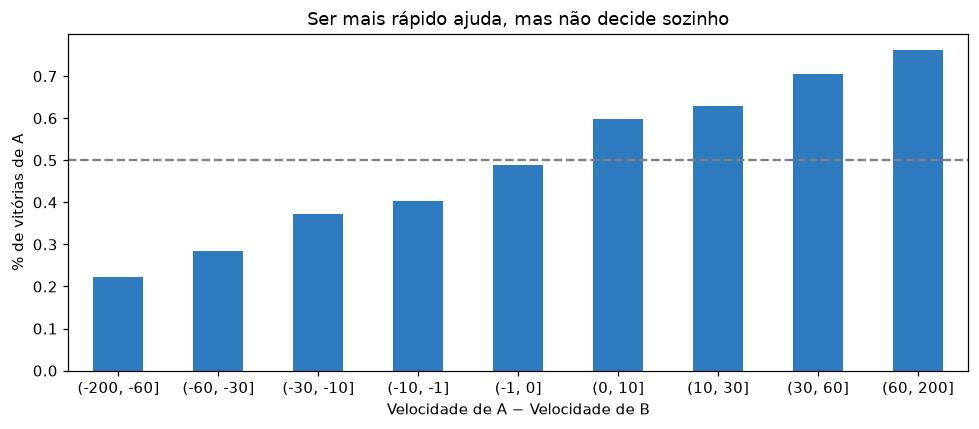

O mais rápido vence em 67.4 % dos confrontos sem empate de velocidade


In [8]:
faixas = pd.cut(eda.dif_speed, [-200, -60, -30, -10, -1, 0, 10, 30, 60, 200])
taxa = eda.groupby(faixas, observed=True).a_vence.mean()
ax = taxa.plot(kind="bar", color="#2f7bbf", figsize=(9, 4))
ax.axhline(0.5, ls="--", c="gray"); ax.set_ylabel("% de vitórias de A")
ax.set_xlabel("Velocidade de A − Velocidade de B"); ax.set_title("Ser mais rápido ajuda, mas não decide sozinho")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
mais_rapido = eda.dif_speed != 0
print("O mais rápido vence em", round(((eda.dif_speed > 0) == eda.a_vence)[mais_rapido].mean() * 100, 1), "% dos confrontos sem empate de velocidade")

**Pergunta 2: a vantagem de tipo muda o resultado?**

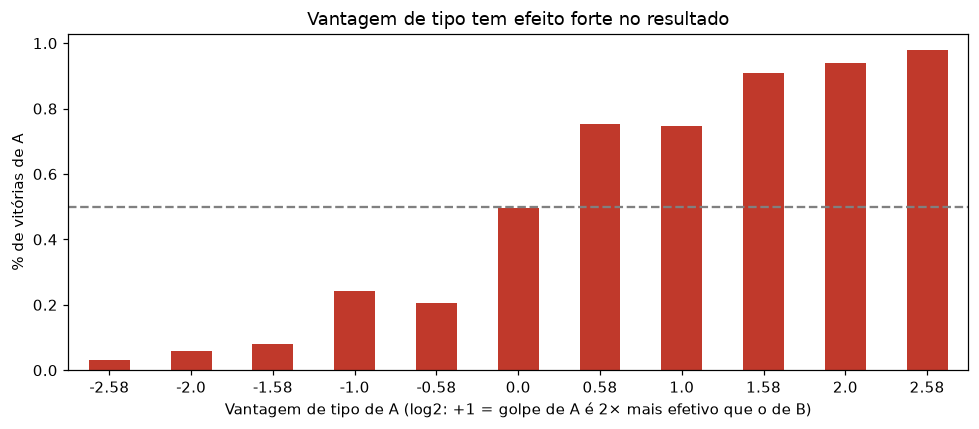

,mean,size
vantagem_tipo,,
-2.58,0.033,214
-2.00,0.059,877
-1.58,0.082,1531
-1.00,0.241,4612
-0.58,0.206,1109
0.00,0.497,13242
0.58,0.754,1132
1.00,0.747,4505
1.58,0.910,1548


In [9]:
tab = eda.groupby("vantagem_tipo").a_vence.agg(["mean", "size"])
tab = tab[tab["size"] >= 100]
ax = tab["mean"].plot(kind="bar", color="#c0392b", figsize=(9, 4))
ax.axhline(0.5, ls="--", c="gray"); ax.set_ylabel("% de vitórias de A")
ax.set_xlabel("Vantagem de tipo de A (log2: +1 = golpe de A é 2× mais efetivo que o de B)")
ax.set_title("Vantagem de tipo tem efeito forte no resultado"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
tab.round(3)

**Pergunta 3: o Pokémon mais forte no geral (maior Total) vence? E quanto a sorte pesa?**

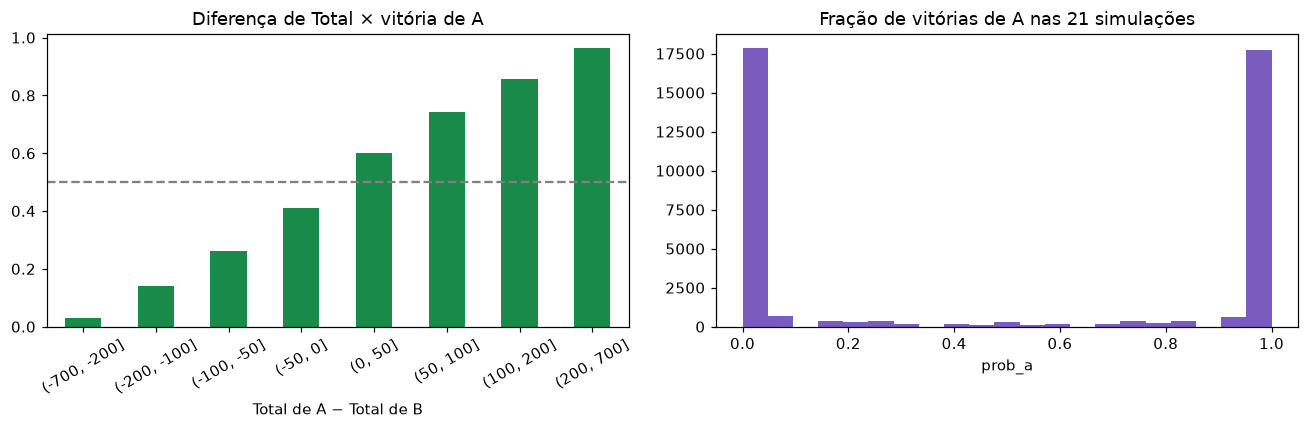

Maior Total vence em 80.6 % dos confrontos
Confrontos totalmente decididos (21×0 ou 21×21): 83.5 %
Confrontos equilibrados (A vence entre 30% e 70%): 2.9 %


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
faixas = pd.cut(eda.dif_total, [-700, -200, -100, -50, 0, 50, 100, 200, 700])
eda.groupby(faixas, observed=True).a_vence.mean().plot(kind="bar", ax=axes[0], color="#1a8a4a")
axes[0].axhline(0.5, ls="--", c="gray"); axes[0].set_title("Diferença de Total × vitória de A")
axes[0].set_xlabel("Total de A − Total de B"); axes[0].tick_params(axis="x", rotation=30)
axes[1].hist(bt.prob_a, bins=21, color="#7a5cbf")
axes[1].set_title("Fração de vitórias de A nas 21 simulações"); axes[1].set_xlabel("prob_a")
plt.tight_layout(); plt.show()
print("Maior Total vence em", round(((eda.dif_total > 0) == eda.a_vence)[eda.dif_total != 0].mean() * 100, 1), "% dos confrontos")
print("Confrontos totalmente decididos (21×0 ou 21×21):", round(bt.prob_a.isin([0, 1]).mean() * 100, 1), "%")
print("Confrontos equilibrados (A vence entre 30% e 70%):", round(bt.prob_a.between(.3, .7).mean() * 100, 1), "%")

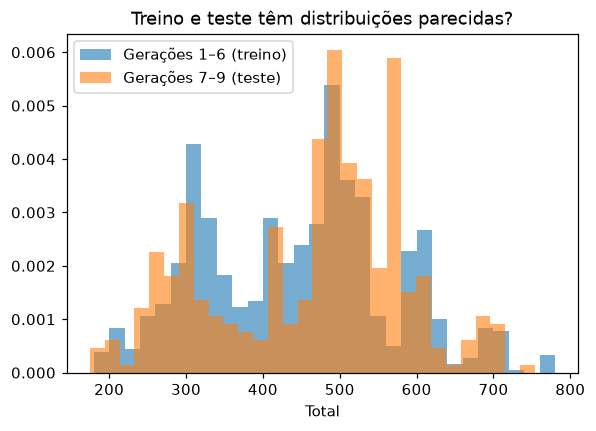

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Total
Generation,,,,,,,
Ger. 1–6,70.0,80.9,75.1,74.3,73.2,69.9,443.4
Ger. 7–9,75.5,86.6,78.5,76.6,74.6,72.6,464.5


In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(pk.loc[pk.Generation <= 6, "Total"], bins=30, alpha=.6, density=True, label="Gerações 1–6 (treino)")
ax.hist(pk.loc[pk.Generation >= 7, "Total"], bins=30, alpha=.6, density=True, label="Gerações 7–9 (teste)")
ax.set_xlabel("Total"); ax.set_title("Treino e teste têm distribuições parecidas?"); ax.legend(); plt.show()
pk.groupby(pk.Generation >= 7)[ATRIBUTOS + ["Total"]].mean().round(1).rename(index={False: "Ger. 1–6", True: "Ger. 7–9"})

### Descobertas da EDA

> Os números exatos estão nas saídas acima.

1. **A velocidade importa, mas não decide sozinha:** o mais rápido vence só **67,4%** dos confrontos. A regra "vence o
   mais rápido" é muito mais fraca aqui do que no dataset público do Kaggle, onde chegava a cerca de 94%.
2. **O tipo tem efeito forte e não linear:** com a maior vantagem de tipo (+2,58 em log2), A vence **97,9%** das vezes, e
   com a maior desvantagem, só **3,3%**. Sem vantagem para nenhum lado, fica em cerca de 50%. O modelo precisa de features
   de tipo, e não só de atributos.
3. **Ser mais forte no geral ajuda mais que ser rápido:** o maior Total vence **80,6%** dos confrontos.
4. **A sorte pesa pouco nesse simulador:** **83,5%** dos confrontos têm o mesmo vencedor nas 21 simulações, e só **2,9%**
   são equilibrados (A vence entre 30% e 70%). Esses equilibrados formam o "teto" de acerto: nenhum modelo pode
   acertá-los sempre.
5. **As gerações 7–9 são um pouco mais fortes** (Total médio 464,5 contra 443,4), mas com distribuições parecidas. A divisão
   por geração é justa, com uma leve mudança de distribuição a monitorar.

## 4. Preparação dos dados

**Features** (tudo que se sabe antes da batalha):
- `dif_<atributo>`: diferença de cada um dos 6 atributos (A − B). Usar diferenças, em vez dos atributos crus dos dois,
  deixa o modelo **simétrico** e reduz a dimensão.
- `mult_a`, `mult_b` (em log2): o quanto o melhor golpe de cada um é efetivo contra o outro, calculado com a tabela oficial
  de tipos. As 18 categorias de tipo viram 2 números, sem precisar de *one-hot* para 18×2×2 colunas.

**Padronização:** `StandardScaler` dentro de um `Pipeline`, então **média e desvio são aprendidos só com o treino** e
aplicados no teste.

In [12]:
def features(df):
    d = add_tipos(juntar(df).rename(columns=lambda c: c.replace(" ", "_")))
    X = pd.DataFrame({f"dif_{a}": d[f"a_{a.replace(' ', '_')}"] - d[f"b_{a.replace(' ', '_')}"] for a in ATRIBUTOS})
    X["log_mult_a"], X["log_mult_b"] = np.log2(d.mult_a), np.log2(d.mult_b)
    return X, d.a_vence.values, d

X_tr, y_tr, d_tr = features(treino)
X_te, y_te, d_te = features(teste)
print("Treino:", X_tr.shape, "| Teste:", X_te.shape)
X_tr.describe().round(2)

Treino: (30000, 8) | Teste: (6000, 8)


,dif_HP,dif_Attack,dif_Defense,dif_Sp. Atk,dif_Sp. Def,dif_Speed,log_mult_a,log_mult_b
count,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00
mean,-0.07,-0.35,-0.54,-0.10,-0.32,0.02,0.74,0.74
std,36.69,46.14,44.16,48.86,40.14,42.34,0.62,0.62
min,-235.00,-170.00,-220.00,-193.00,-210.00,-165.00,-1.42,-2.00
25%,-20.00,-30.00,-28.00,-31.00,-25.00,-30.00,0.58,0.58
50%,0.00,0.00,0.00,0.00,0.00,0.00,0.58,0.58
75%,20.00,30.00,26.00,30.00,25.00,30.00,1.58,1.58
max,249.00,175.00,210.00,186.00,200.00,155.00,2.58,2.58


## 5. Baselines

| Baseline | Por que |
|---|---|
| **Classe majoritária** | Referência mínima: qualquer modelo precisa superar o "chute". |
| **Vence o mais rápido** | Regra intuitiva de quem joga; é o principal concorrente do SVM. |
| **Vence o maior Total** | "O mais forte no geral vence". |
| **Regressão Logística** | Modelo linear clássico com as mesmas features: o SVM precisa acrescentar valor sobre ele. |

**Métricas:** acurácia (classes equilibradas), F1 e ROC-AUC (qualidade da ordenação/confiança).

In [13]:
class Regra(BaseEstimator, ClassifierMixin):
    """Baseline sem aprendizado: A vence se a coluna escolhida for > 0 (empate: sorteio fixo pela seed)."""
    def __init__(self, coluna):
        self.coluna = coluna
    def fit(self, X, y):
        self.classes_ = np.array([0, 1]); return self
    def decision_function(self, X):
        return X[self.coluna].values.astype(float)
    def predict(self, X):
        s = self.decision_function(X)
        empate = np.random.default_rng(SEED).integers(0, 2, len(s))
        return np.where(s > 0, 1, np.where(s < 0, 0, empate))

X_tr_regra, X_te_regra = X_tr.assign(dif_total=d_tr.a_Total - d_tr.b_Total), X_te.assign(dif_total=d_te.a_Total - d_te.b_Total)
resultados = {}

def avaliar(nome, modelo, Xtr=X_tr, Xte=X_te):
    modelo.fit(Xtr, y_tr)
    pred = modelo.predict(Xte)
    score = modelo.decision_function(Xte) if hasattr(modelo, "decision_function") else modelo.predict_proba(Xte)[:, 1]
    resultados[nome] = {"acuracia": accuracy_score(y_te, pred), "f1": f1_score(y_te, pred),
                        "roc_auc": roc_auc_score(y_te, score)}
    return modelo

avaliar("Baseline: classe majoritária", DummyClassifier(strategy="most_frequent"))
avaliar("Baseline: vence o mais rápido", Regra("dif_Speed"))
avaliar("Baseline: vence o maior Total", Regra("dif_total"), X_tr_regra, X_te_regra)
avaliar("Regressão Logística", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))
pd.DataFrame(resultados).T.round(3)

,acuracia,f1,roc_auc
Baseline: classe majoritária,0.496,0.000,0.500
Baseline: vence o mais rápido,0.674,0.678,0.701
Baseline: vence o maior Total,0.795,0.797,0.885
Regressão Logística,0.910,0.911,0.975


## 6. Primeiro modelo: SVM (kernel RBF, parâmetros padrão)

Primeira versão, **sem ajuste de hiperparâmetros**: o objetivo do Checkpoint 1 é ter o fluxo funcionando de ponta a
ponta. Os experimentos (kernel, C, gamma, features) ficam para o Checkpoint 2.

In [14]:
import time
t0 = time.time()
svm = avaliar("SVM RBF (padrão)", make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")))
print(f"Treino + teste em {time.time() - t0:.0f}s | vetores de suporte: {svm[-1].n_support_.sum()} de {len(y_tr)} exemplos")
tabela = pd.DataFrame(resultados).T.round(3).sort_values("acuracia", ascending=False)
tabela

Treino + teste em 10s | vetores de suporte: 5818 de 30000 exemplos


,acuracia,f1,roc_auc
SVM RBF (padrão),0.922,0.922,0.981
Regressão Logística,0.910,0.911,0.975
Baseline: vence o maior Total,0.795,0.797,0.885
Baseline: vence o mais rápido,0.674,0.678,0.701
Baseline: classe majoritária,0.496,0.000,0.500


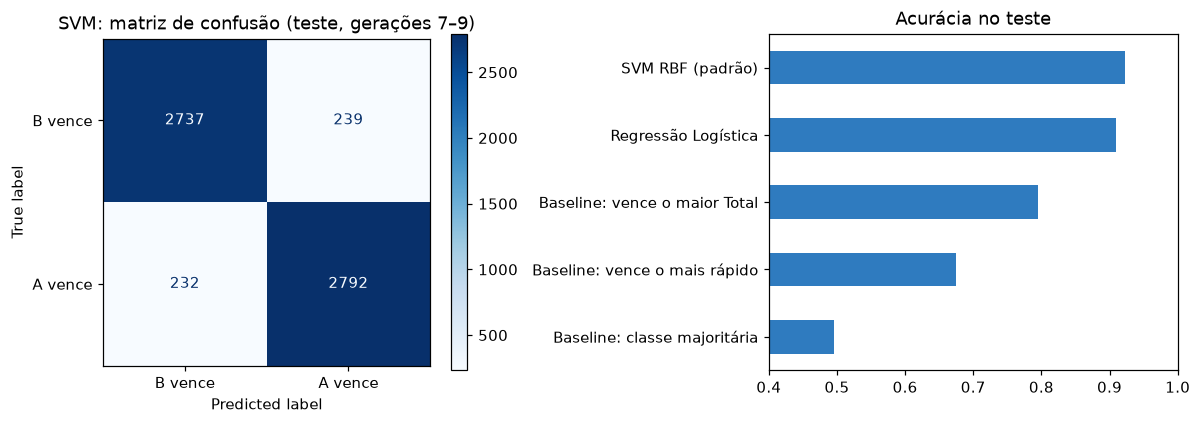

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_te, svm.predict(X_te), display_labels=["B vence", "A vence"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("SVM: matriz de confusão (teste, gerações 7–9)")
tabela["acuracia"].sort_values().plot(kind="barh", ax=axes[1], color="#2f7bbf")
axes[1].set_xlim(0.4, 1); axes[1].set_title("Acurácia no teste"); plt.tight_layout(); plt.show()

### Erros do SVM e o teto de acerto

Como existe sorte na batalha, alguns confrontos são equilibrados. Vemos onde o SVM erra em relação à `prob_a` real:

In [16]:
d_te["pred_svm"] = svm.predict(X_te)
d_te["erro"] = d_te.pred_svm != d_te.a_vence
d_te["equilibrado"] = d_te.prob_a.between(.3, .7)
print("Taxa de erro em confrontos equilibrados:", round(d_te.loc[d_te.equilibrado, "erro"].mean(), 3))
print("Taxa de erro em confrontos decididos:   ", round(d_te.loc[~d_te.equilibrado, "erro"].mean(), 3))
d_te.loc[d_te.erro & ~d_te.equilibrado, ["a_name", "b_name", "prob_a", "a_Speed", "b_Speed", "mult_a", "mult_b"]].head(10)

Taxa de erro em confrontos equilibrados: 0.505
Taxa de erro em confrontos decididos:    0.064


,a_name,b_name,prob_a,a_Speed,b_Speed,mult_a,mult_b
4,rowlet,hakamo-o,0.8571,42,65,3.0,1.5
45,decidueye,mimikyu-disguised,0.1429,70,96,3.0,3.0
62,litten,wishiwashi-solo,0.8095,70,40,1.0,3.0
69,litten,clobbopus,0.0476,70,32,1.5,1.5
74,litten,greavard,0.0952,70,34,1.5,1.5
102,incineroar,crabrawler,0.0952,60,63,1.5,3.0
104,incineroar,pheromosa,0.9048,60,151,3.0,3.0
154,primarina,polteageist,0.0476,60,70,1.5,1.5
172,pikipek,thwackey,0.0952,65,80,3.0,1.0
203,toucannon,greedent,0.0952,60,20,1.5,1.5


## 7. Demonstração: prever um confronto qualquer

Base do protótipo: escolher dois Pokémon de qualquer geração e prever o favorito.

In [17]:
nome_para_id = pk.set_index("name")["pokeapi_id"]

from simulador import Lutador, simular_confronto
lutador = {r["name"]: Lutador.de_linha(r) for _, r in pk.iterrows()}

def prever(a, b, modelo=svm):
    df = pd.DataFrame({"a_id": [nome_para_id[a]], "b_id": [nome_para_id[b]], "a_vence": [0]})
    X, _, _ = features(df)
    s = modelo.decision_function(X)[0]
    fav = a if s > 0 else b
    real = simular_confronto(lutador[a], lutador[b], np.random.default_rng(SEED), 201) / 201
    fav_real = a if real > .5 else b
    ok = "✔" if fav == fav_real else "✘"
    print(f"{a:>12} × {b:<12} → SVM: {fav:<12} (score {s:+.2f}) | simulador: {a} vence {real:.0%} {ok}")

for a, b in [("charizard", "blastoise"), ("pikachu", "gyarados"), ("garchomp", "weavile"),
             ("meowscarada", "skeledirge"), ("koraidon", "miraidon"), ("snorlax", "gengar")]:
    prever(a, b)

   charizard × blastoise    → SVM: blastoise    (score -2.24) | simulador: charizard vence 0% ✔
     pikachu × gyarados     → SVM: pikachu      (score +0.21) | simulador: pikachu vence 10% ✘
    garchomp × weavile      → SVM: weavile      (score -2.32) | simulador: garchomp vence 0% ✔
 meowscarada × skeledirge   → SVM: meowscarada  (score +0.82) | simulador: meowscarada vence 84% ✔
    koraidon × miraidon     → SVM: koraidon     (score +0.11) | simulador: koraidon vence 55% ✔
     snorlax × gengar       → SVM: snorlax      (score +0.25) | simulador: snorlax vence 43% ✘


**Pikachu × Gyarados** é um erro instrutivo: o SVM vê a vantagem de tipo enorme (elétrico 4× contra Gyarados) e aposta no
Pikachu. Pelas contas do simulador, porém, o Pikachu causa quase exatamente o HP do Gyarados e **só nocauteia com golpe
crítico**, enquanto o Gyarados nocauteia o Pikachu em um golpe. Esse "limiar de nocaute" é uma não linearidade difícil
para o modelo e será investigado na análise de erros.

In [18]:
import joblib, os
os.makedirs("../modelos", exist_ok=True)
joblib.dump(svm, "../modelos/svm_duelo_v1.joblib")
print("Modelo salvo em modelos/svm_duelo_v1.joblib")

Modelo salvo em modelos/svm_duelo_v1.joblib


## 8. Resumo do pipeline e próximos passos

**Fluxo executado:** dados brutos (PokéAPI) → `montar_base.py` → `gerar_batalhas.py` (simulador, seed 42) → features
(diferença de atributos + vantagem de tipo) → divisão por geração (sem vazamento) → padronização no treino → baselines e
SVM → métricas no teste com Pokémon nunca vistos → modelo salvo.

**Hipóteses e experimentos para o Checkpoint 2 (03/11):**
- **E1:** kernel linear × RBF × polinomial. A interação entre velocidade e tipo exige uma fronteira não linear?
- **E2:** SVM só com atributos × atributos + tipos. Quanto do acerto vem do tipo?
- **E3:** efeito de C e gamma (busca em grade com validação cruzada **agrupada por Pokémon**).
- **E4:** divisão aleatória das batalhas × divisão por Pokémon. Medir o tamanho do otimismo causado pelo vazamento.
- **E5:** análise dos erros (Shedinja, imunidades, Pokémon com atributos extremos) e comparação com a `prob_a` real.
- **Extra:** testar o modelo nas batalhas do dataset público (*Pokemon Challenge*, Kaggle), gerado por outro simulador.